# Industrial Sensor Anomaly Detection Using Time-RCD

Zero-shot anomaly detection on the **SKAB** (Skoltech Anomaly Benchmark) industrial water-circulation dataset
using the pretrained Hugging Face model **thu-sail-lab/Time-RCD**.

**Research question:** Can a pretrained zero-shot time-series foundation model detect the labeled fault periods
in SKAB without any training on SKAB, and how does it compare with simple classical baselines?

Pipeline: download data → EDA → score every experiment with Time-RCD → choose a threshold on validation
experiments only → evaluate on held-out test experiments → compare with baselines.

Run all cells from top to bottom. The two scoring cells take about 5 and 10 minutes on a CPU the first time;
afterwards they reuse the saved score files in `results/`.

In [1]:
import os, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)

# Work from the repository root whether this notebook is started from notebook/ or from the root.
if Path.cwd().name == "notebook":
    os.chdir(Path.cwd().parent)
DATA_DIR = Path("data/skab")
RESULTS = Path("results")
FIG = RESULTS / "figures"
for p in (DATA_DIR, FIG):
    p.mkdir(parents=True, exist_ok=True)

RAW_URL = "https://raw.githubusercontent.com/waico/SKAB/master/data"
SENSOR_COLUMNS = ["Accelerometer1RMS", "Accelerometer2RMS", "Current", "Pressure",
                  "Temperature", "Thermocouple", "Voltage", "Volume Flow RateRMS"]

# Every labeled experiment file, as (group, number).
EXPERIMENTS = ([("valve1", i) for i in range(16)] + [("valve2", i) for i in range(4)]
               + [("other", i) for i in range(1, 15)])

# Experiment-level split, fixed before looking at any model output.
# Validation is used only to choose the anomaly threshold. The "other" picks cover one scenario
# each: fluid leak (1), rotor imbalance (5), water amount (10), cavitation (13).
VALIDATION = [("valve1", 0), ("valve1", 1), ("valve1", 2), ("valve1", 3), ("valve1", 4),
              ("valve2", 0), ("other", 1), ("other", 5), ("other", 10), ("other", 13)]
TEST = [e for e in EXPERIMENTS if e not in VALIDATION]
name = lambda e: f"{e[0]}/{e[1]}"
VAL_NAMES, TEST_NAMES = [name(e) for e in VALIDATION], [name(e) for e in TEST]


def experiment_path(group, number):
    return DATA_DIR / group / f"{number}.csv"


def load_experiment(path):
    """Load one SKAB CSV (';' separated) in chronological order."""
    df = pd.read_csv(path, sep=";", parse_dates=["datetime"])
    return df.sort_values("datetime").reset_index(drop=True)


print("experiments:", len(EXPERIMENTS), "| validation:", len(VALIDATION), "| test:", len(TEST))

experiments: 34 | validation: 10 | test: 24


## 1. Download the dataset

SKAB is distributed from its GitHub repository (GPL-3.0). Each file is one experiment on the test rig.

In [2]:
files = [(experiment_path(g, n), f"{RAW_URL}/{g}/{n}.csv") for g, n in EXPERIMENTS]
files.append((DATA_DIR / "anomaly-free" / "anomaly-free.csv", f"{RAW_URL}/anomaly-free/anomaly-free.csv"))
for path, url in files:
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(url, path)
print("files available:", sum(p.exists() for p, _ in files), "of", len(files))

files available: 35 of 35


## 2. Exploratory data analysis

In [3]:
data = {e: load_experiment(experiment_path(*e)) for e in EXPERIMENTS}
normal = load_experiment(DATA_DIR / "anomaly-free" / "anomaly-free.csv")
all_rows = pd.concat(data.values(), ignore_index=True)

print("total labeled rows:", len(all_rows), "| anomaly-free rows:", len(normal))
print("columns:", list(all_rows.columns))
print("dtypes:", all_rows.dtypes.astype(str).to_dict())
dups_within = sum(int(df.duplicated().sum()) for df in data.values())
print("missing values:", int(all_rows.isna().sum().sum()), "| duplicate rows within an experiment:", dups_within)
steps = pd.concat([df["datetime"].diff().dt.total_seconds() for df in data.values()]).dropna()
print("time step: %.0f%% of rows are 1 s apart, max gap %d s" % (100 * (steps == 1).mean(), steps.max()))
print("label values:", sorted(all_rows["anomaly"].unique()), "(0 = normal, 1 = anomaly, per SKAB documentation)")
lengths = pd.Series({name(e): len(df) for e, df in data.items()})
print("rows per experiment: min %d, median %d, max %d" % (lengths.min(), lengths.median(), lengths.max()))
all_rows[SENSOR_COLUMNS].describe().loc[["mean", "std", "min", "max"]].round(3).T

total labeled rows: 37401 | anomaly-free rows: 9405
columns: ['datetime', 'Accelerometer1RMS', 'Accelerometer2RMS', 'Current', 'Pressure', 'Temperature', 'Thermocouple', 'Voltage', 'Volume Flow RateRMS', 'anomaly', 'changepoint']
dtypes: {'datetime': 'datetime64[us]', 'Accelerometer1RMS': 'float64', 'Accelerometer2RMS': 'float64', 'Current': 'float64', 'Pressure': 'float64', 'Temperature': 'float64', 'Thermocouple': 'float64', 'Voltage': 'float64', 'Volume Flow RateRMS': 'float64', 'anomaly': 'float64', 'changepoint': 'float64'}


missing values: 0 | duplicate rows within an experiment: 0
time step: 95% of rows are 1 s apart, max gap 247 s
label values: [np.float64(0.0), np.float64(1.0)] (0 = normal, 1 = anomaly, per SKAB documentation)
rows per experiment: min 745, median 1140, max 1327


,mean,std,min,max
Accelerometer1RMS,0.108,0.134,0.016,0.723
Accelerometer2RMS,0.136,0.151,0.016,0.800
Current,1.464,0.741,0.150,3.318
Pressure,0.071,0.261,-1.257,1.694
Temperature,76.794,8.832,65.089,95.011
Thermocouple,26.054,2.644,22.021,33.415
Voltage,229.824,10.932,200.744,255.324
Volume Flow RateRMS,63.031,42.520,0.556,133.688


### Observation A: class distribution

normal=24334 (65.1%), anomaly=13067 (34.9%)
anomaly fraction per experiment: min 0.25, median 0.35, max 0.49


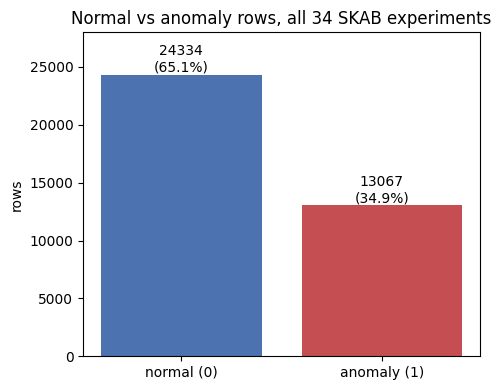

In [4]:
counts = all_rows["anomaly"].value_counts().sort_index()
pct = 100 * counts / counts.sum()
print("normal=%d (%.1f%%), anomaly=%d (%.1f%%)" % (counts[0], pct[0], counts[1], pct[1]))
per_exp_frac = pd.Series({name(e): df["anomaly"].mean() for e, df in data.items()})
print("anomaly fraction per experiment: min %.2f, median %.2f, max %.2f" % (per_exp_frac.min(), per_exp_frac.median(), per_exp_frac.max()))

plt.figure(figsize=(5, 4))
plt.bar(["normal (0)", "anomaly (1)"], counts.values, color=["#4C72B0", "#C44E52"])
for i, v in enumerate(counts.values):
    plt.text(i, v, f"{v}\n({pct.iloc[i]:.1f}%)", ha="center", va="bottom")
plt.ylabel("rows"); plt.ylim(0, counts.max() * 1.15)
plt.title("Normal vs anomaly rows, all 34 SKAB experiments")
plt.tight_layout(); plt.savefig(FIG / "fig2_class_distribution.png", dpi=150); plt.show()

### Observation B: sensor correlations, normal vs anomalous periods

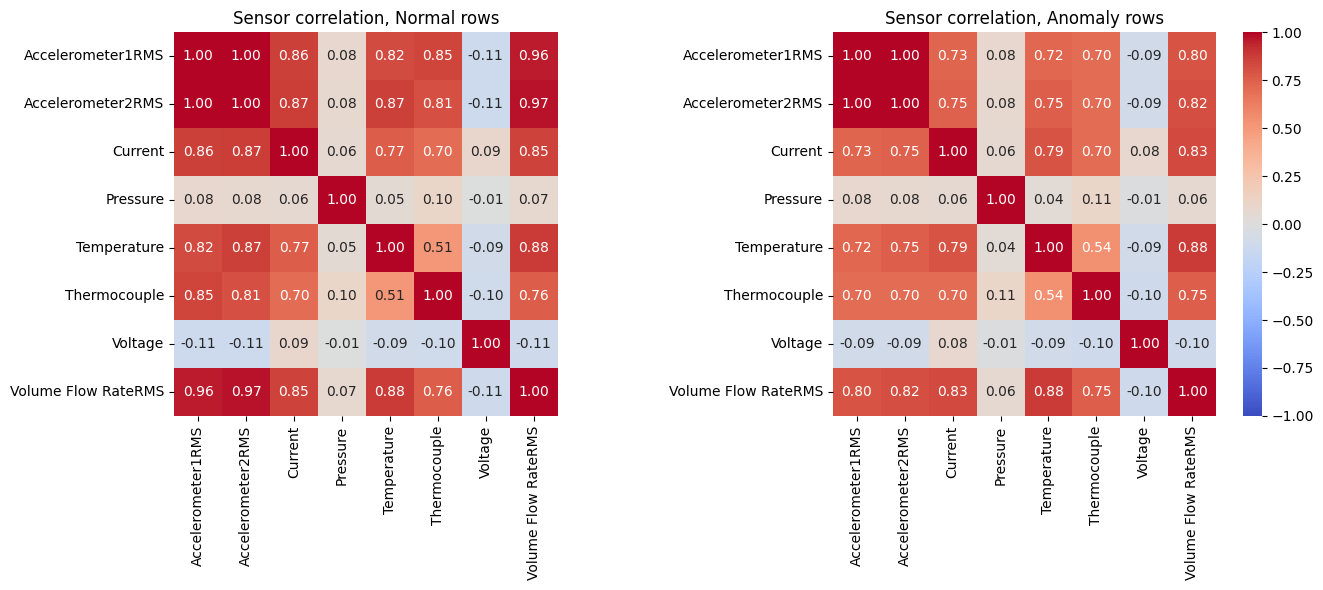

strongest sensor correlations (all rows):
  Accelerometer1RMS  Accelerometer2RMS    r=1.00  (normal 1.00, anomaly 1.00)
  Temperature        Volume Flow RateRMS  r=0.88  (normal 0.88, anomaly 0.88)
  Current            Volume Flow RateRMS  r=0.84  (normal 0.85, anomaly 0.83)
  Accelerometer2RMS  Volume Flow RateRMS  r=0.83  (normal 0.97, anomaly 0.82)
  Accelerometer1RMS  Volume Flow RateRMS  r=0.81  (normal 0.96, anomaly 0.80)


In [5]:
corr_all = all_rows[SENSOR_COLUMNS].corr()
corr_norm = all_rows[all_rows["anomaly"] == 0][SENSOR_COLUMNS].corr()
corr_anom = all_rows[all_rows["anomaly"] == 1][SENSOR_COLUMNS].corr()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, corr, title in [(axes[0], corr_norm, "Normal rows"), (axes[1], corr_anom, "Anomaly rows")]:
    sns.heatmap(corr, ax=ax, vmin=-1, vmax=1, cmap="coolwarm", annot=True, fmt=".2f", square=True, cbar=ax is axes[1])
    ax.set_title(f"Sensor correlation, {title}")
plt.tight_layout(); plt.savefig(FIG / "fig3_correlation_heatmap.png", dpi=150); plt.show()

pairs = corr_all.where(np.triu(np.ones_like(corr_all, dtype=bool), k=1)).stack().sort_values(key=abs, ascending=False)
print("strongest sensor correlations (all rows):")
for (a, b), r in pairs.head(5).items():
    print("  %-18s %-20s r=%.2f  (normal %.2f, anomaly %.2f)" % (a, b, r, corr_norm.loc[a, b], corr_anom.loc[a, b]))

### Observation C: anomaly duration

In [6]:
runs = []
for df in data.values():
    lab = df["anomaly"].to_numpy()
    edges = np.diff(np.concatenate([[0], lab, [0]]))
    runs += list(np.where(edges == -1)[0] - np.where(edges == 1)[0])
runs = np.array(runs)
print("anomaly segments: %d total; length min %d, median %d, max %d rows (1 row = 1 second)"
      % (len(runs), runs.min(), np.median(runs), runs.max()))
print("segments of length 1 (point anomalies):", int((runs == 1).sum()))

anomaly segments: 34 total; length min 188, median 399, max 586 rows (1 row = 1 second)
segments of length 1 (point anomalies): 0


### Figure 1: sensor readings over time for one experiment

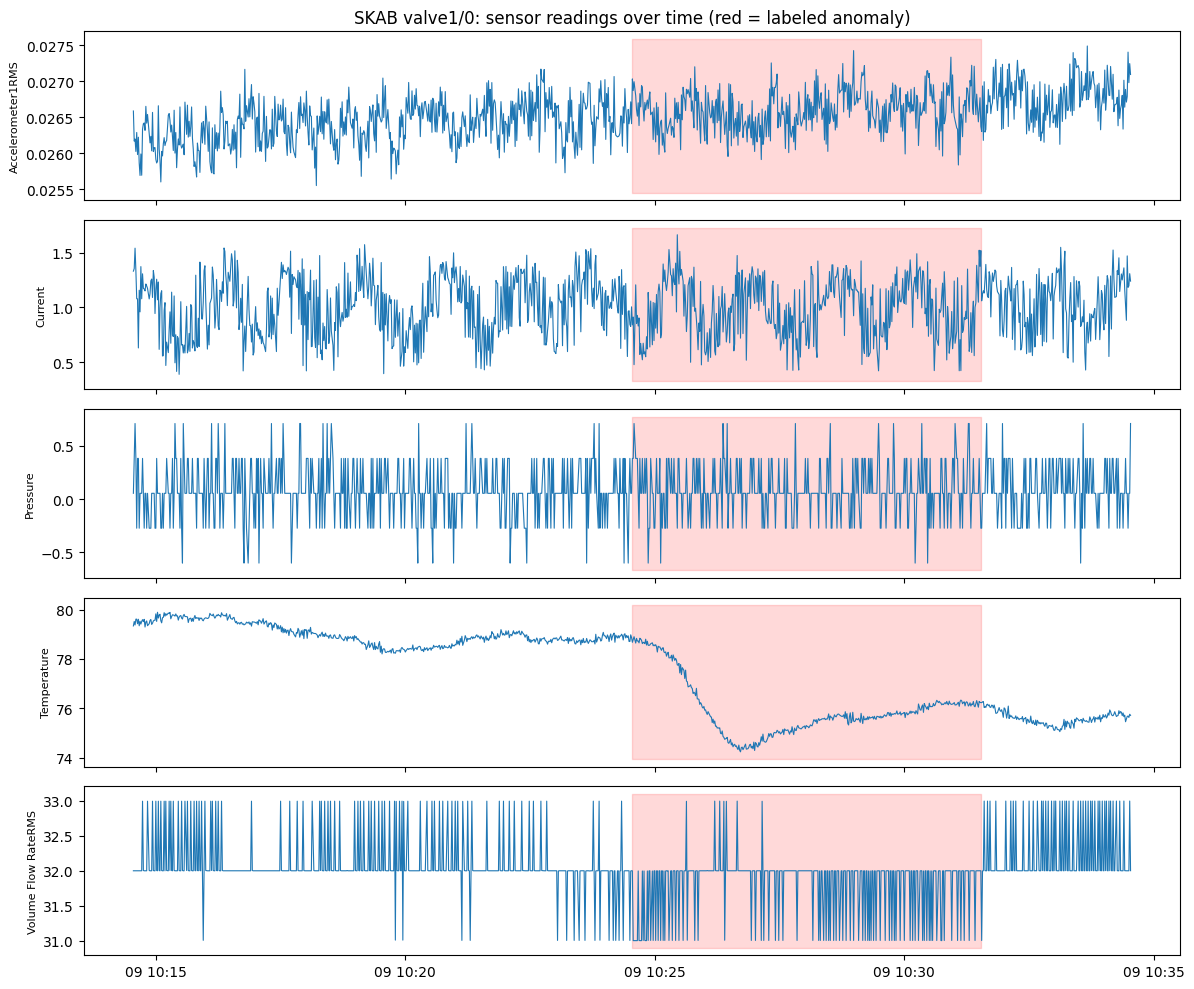

In [7]:
df = data[("valve1", 0)]
show = ["Accelerometer1RMS", "Current", "Pressure", "Temperature", "Volume Flow RateRMS"]
fig, axes = plt.subplots(len(show), 1, figsize=(12, 10), sharex=True)
for ax, col in zip(axes, show):
    ax.plot(df["datetime"], df[col], lw=0.8)
    lo, hi = ax.get_ylim()
    ax.fill_between(df["datetime"], lo, hi, where=df["anomaly"] == 1, color="red", alpha=0.15)
    ax.set_ylabel(col, fontsize=8)
axes[0].set_title("SKAB valve1/0: sensor readings over time (red = labeled anomaly)")
plt.tight_layout(); plt.savefig(FIG / "fig1_sensors_over_time.png", dpi=150); plt.show()

## 3. Score every experiment with Time-RCD

Time-RCD is a zero-shot foundation model: given a multivariate series of shape (T, C) it returns one anomaly
score in [0, 1] per time step, with no training on our data. Only the 8 sensor columns are passed to the model;
the `anomaly` and `changepoint` label columns are never used as input.

In [8]:
from time_rcd import TimeRCDDetector

SCORES_CSV = RESULTS / "scores.csv"
if SCORES_CSV.exists():
    print("using saved scores:", SCORES_CSV)
else:
    detector = TimeRCDDetector.from_pretrained(variant="multi", device="cpu")
    todo = [(name(e), experiment_path(*e)) for e in EXPERIMENTS] + [("anomaly-free/0", DATA_DIR / "anomaly-free" / "anomaly-free.csv")]
    frames = []
    for exp, path in todo:
        df = load_experiment(path)
        df["anomaly_score"] = detector.predict(df[SENSOR_COLUMNS].to_numpy())
        df.insert(0, "experiment", exp)
        frames.append(df)
        print("scored", exp, len(df), "rows")
    pd.concat(frames, ignore_index=True).to_csv(SCORES_CSV, index=False)

scores = pd.read_csv(SCORES_CSV, parse_dates=["datetime"])
# Time-RCD scores are relative to each recording's own context, so their scale differs between
# experiments. We convert each experiment's scores to percentile ranks (label-free) for thresholding.
scores["rank"] = scores.groupby("experiment")["anomaly_score"].rank(pct=True)
scores.groupby("experiment")["anomaly_score"].agg(["max", "median"]).round(3).T

C:\Users\Asir\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


scored valve1/0 1147 rows


scored valve1/1 1145 rows


scored valve1/2 1075 rows


scored valve1/3 1148 rows


scored valve1/4 1095 rows


... (26 outputs left out)

scored other/13 923 rows


scored other/14 905 rows


scored anomaly-free/0 9405 rows


experiment,anomaly-free/0,other/1,other/10,other/11,other/12,other/13,other/14,other/2,other/3,other/4,...,valve1/4,valve1/5,valve1/6,valve1/7,valve1/8,valve1/9,valve2/0,valve2/1,valve2/2,valve2/3
max,0.997,0.569,0.898,0.998,1.000,0.996,1.000,0.853,0.694,0.289,...,0.775,0.536,0.798,0.517,0.535,0.427,1.00,0.159,1.000,0.546
median,0.017,0.022,0.012,0.013,0.006,0.006,0.001,0.019,0.019,0.024,...,0.012,0.022,0.010,0.052,0.024,0.017,0.01,0.025,0.004,0.032


### Side experiment: the univariate checkpoint, one sensor at a time

The model card reports better benchmark numbers for the univariate checkpoint. We score each of the 8 sensors
separately and average the scores, to compare against the multivariate model in Section 6.

In [9]:
UNI_CSV = RESULTS / "scores_uni.csv"
if UNI_CSV.exists():
    print("using saved scores:", UNI_CSV)
else:
    det_uni = TimeRCDDetector.from_pretrained(variant="uni", device="cpu")
    frames = []
    for e in EXPERIMENTS:
        df = load_experiment(experiment_path(*e))
        per = np.column_stack([det_uni.predict(df[c].to_numpy()) for c in SENSOR_COLUMNS])
        frames.append(pd.DataFrame({"experiment": name(e), "anomaly": df["anomaly"], "uni_mean": per.mean(1)}))
        print("scored", name(e))
    pd.concat(frames, ignore_index=True).to_csv(UNI_CSV, index=False)
scores_uni = pd.read_csv(UNI_CSV)

scored valve1/0


scored valve1/1


scored valve1/2


scored valve1/3


scored valve1/4


scored valve1/5


... (24 outputs left out)

scored other/11


scored other/12


scored other/13


scored other/14


## 4. Threshold selection (validation only) and test evaluation

The threshold is the within-experiment rank that maximises F1 on the 10 validation experiments. It is then
frozen and applied to the 24 test experiments, whose labels are used only for reporting metrics.

In [10]:
val = scores[scores["experiment"].isin(VAL_NAMES)]
test = scores[scores["experiment"].isin(TEST_NAMES)]
normal_only = scores[scores["experiment"] == "anomaly-free/0"]


def metrics(y, s, thr):
    pred = (s >= thr).astype(int)
    return {"accuracy": accuracy_score(y, pred), "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred), "f1": f1_score(y, pred), "roc_auc": roc_auc_score(y, s)}


candidates = np.linspace(0.30, 0.99, 70)
f1s = [f1_score(val["anomaly"], val["rank"] >= t) for t in candidates]
THRESHOLD = float(candidates[int(np.argmax(f1s))])
print("validation rows: %d | chosen rank threshold = %.3f (validation F1 = %.3f)" % (len(val), THRESHOLD, max(f1s)))

pooled = metrics(test["anomaly"], test["rank"], THRESHOLD)
print("\nTEST (%d rows, %d experiments):" % (len(test), len(TEST)))
for k, v in pooled.items():
    print("  %-10s %.3f" % (k, v))
cm = confusion_matrix(test["anomaly"], test["rank"] >= THRESHOLD)
print("  confusion matrix [[TN FP] [FN TP]]:", cm.tolist())
print("  trivial 'everything is anomaly' F1 for comparison: %.3f" % f1_score(test["anomaly"], np.ones(len(test))))

ref_thr = np.quantile(normal_only["anomaly_score"], 0.95)
ref = metrics(test["anomaly"], test["anomaly_score"], ref_thr)
print("  reference, model-tutorial method (raw score >= 95%% quantile of anomaly-free = %.3f): precision %.3f, recall %.3f, F1 %.3f"
      % (ref_thr, ref["precision"], ref["recall"], ref["f1"]))

per_exp = (test.groupby("experiment")
           .apply(lambda d: pd.Series(metrics(d["anomaly"], d["rank"], THRESHOLD)), include_groups=False)
           .sort_values("f1"))
evaluation = pd.concat([per_exp, pd.DataFrame([pooled], index=["ALL TEST (pooled)"])]).round(3)
evaluation.index.name = "experiment"
evaluation.to_csv(RESULTS / "evaluation.csv")
print("\nper-experiment test ROC-AUC: min %.2f, median %.2f, max %.2f" % (per_exp["roc_auc"].min(), per_exp["roc_auc"].median(), per_exp["roc_auc"].max()))
evaluation

validation rows: 10885 | chosen rank threshold = 0.310 (validation F1 = 0.562)

TEST (26516 rows, 24 experiments):
  accuracy   0.587
  precision  0.456
  recall     0.895
  f1         0.604
  roc_auc    0.737
  confusion matrix [[TN FP] [FN TP]]: [[7224, 9961], [982, 8349]]
  trivial 'everything is anomaly' F1 for comparison: 0.521
  reference, model-tutorial method (raw score >= 95% quantile of anomaly-free = 0.102): precision 0.565, recall 0.247, F1 0.343



per-experiment test ROC-AUC: min 0.21, median 0.79, max 1.00


,accuracy,precision,recall,f1,roc_auc
experiment,,,,,
valve2/3,0.260,0.252,0.438,0.320,0.209
other/3,0.459,0.362,0.714,0.480,0.400
valve1/5,0.508,0.396,0.784,0.527,0.511
valve1/10,0.511,0.399,0.788,0.530,0.591
other/4,0.522,0.394,0.820,0.532,0.652
valve1/6,0.527,0.412,0.810,0.546,0.418
other/8,0.544,0.424,0.834,0.562,0.709
valve1/15,0.550,0.428,0.842,0.568,0.601
valve2/2,0.570,0.442,0.873,0.587,0.619


### Figure 4: model scores vs ground truth (strong, median, and weak test experiment)

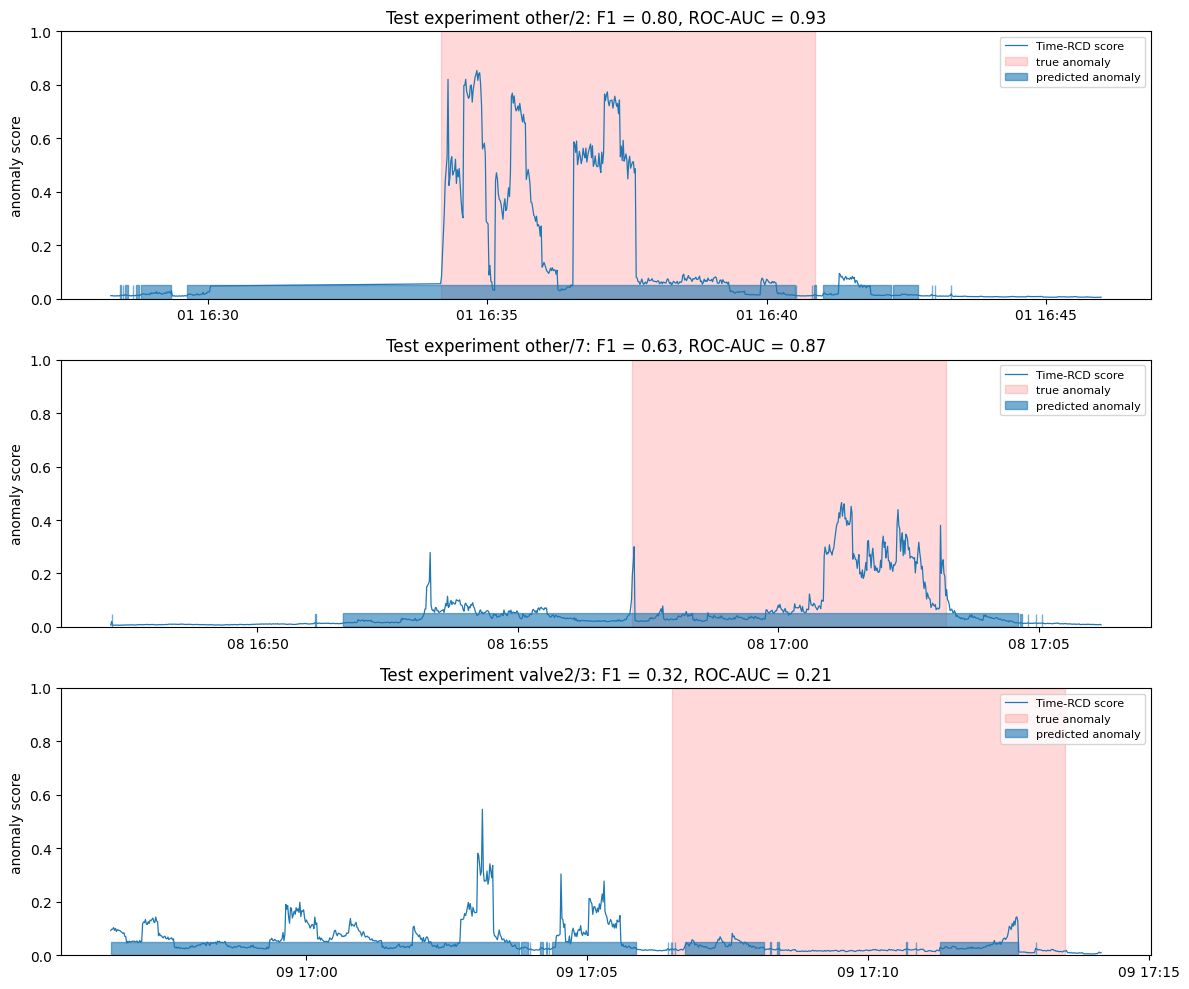

In [11]:
picks = [per_exp.index[-1], per_exp.index[len(per_exp) // 2], per_exp.index[0]]
fig, axes = plt.subplots(len(picks), 1, figsize=(12, 10))
for ax, exp in zip(axes, picks):
    d = test[test["experiment"] == exp]
    pred = d["rank"] >= THRESHOLD
    ax.plot(d["datetime"], d["anomaly_score"], lw=0.9, label="Time-RCD score")
    ax.fill_between(d["datetime"], 0, 1, where=d["anomaly"] == 1, color="red", alpha=0.15, label="true anomaly")
    ax.fill_between(d["datetime"], 0, 0.05, where=pred, color="C0", alpha=0.6, label="predicted anomaly")
    ax.set_ylim(0, 1); ax.set_ylabel("anomaly score")
    ax.set_title(f"Test experiment {exp}: F1 = {per_exp.loc[exp, 'f1']:.2f}, ROC-AUC = {per_exp.loc[exp, 'roc_auc']:.2f}")
    ax.legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "fig4_actual_vs_predicted.png", dpi=150); plt.show()

### Figure 5: confusion matrix on the test set

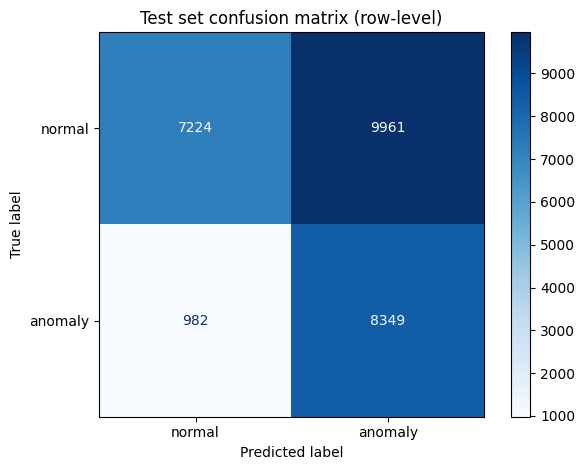

In [12]:
ConfusionMatrixDisplay(cm, display_labels=["normal", "anomaly"]).plot(cmap="Blues", values_format="d")
plt.title("Test set confusion matrix (row-level)")
plt.tight_layout(); plt.savefig(FIG / "fig5_confusion_matrix.png", dpi=150); plt.show()

## 5. Five representative examples

Each row is a single test time step: its sensor readings, true label, raw model score, within-experiment rank,
and the prediction at the frozen threshold.

In [13]:
t = test.assign(pred=(test["rank"] >= THRESHOLD).astype(int))
cols = ["experiment", "datetime", "Volume Flow RateRMS", "Temperature", "Current", "anomaly", "anomaly_score", "rank", "pred"]
tn = t[(t.anomaly == 0) & (t.pred == 0)].sort_values("rank")
ex = {
    "1 normal, correctly normal": tn.iloc[len(tn) // 2],
    "2 anomaly, detected": t[(t.anomaly == 1) & (t.pred == 1)].sort_values("anomaly_score").iloc[-1],
    "3 anomaly, missed": t[(t.anomaly == 1) & (t.pred == 0)].sort_values("rank").iloc[0],
    "4 normal, false alarm": t[(t.anomaly == 0) & (t.pred == 1)].sort_values("anomaly_score").iloc[-1],
}
# 5: start of the longest stretch of consecutive correctly detected anomaly rows
best = (None, 0, None)
for exp, d in t.groupby("experiment"):
    hit = ((d.anomaly == 1) & (d.pred == 1)).to_numpy().astype(int)
    edges = np.diff(np.concatenate([[0], hit, [0]]))
    starts, ends = np.where(edges == 1)[0], np.where(edges == -1)[0]
    if len(starts) and (ends - starts).max() > best[1]:
        i = int(np.argmax(ends - starts)); best = (exp, int((ends - starts)[i]), d.iloc[starts[i]])
ex["5 prolonged anomaly, detected"] = best[2]
print("longest correctly detected stretch: %d consecutive seconds in %s" % (best[1], best[0]))
examples = pd.DataFrame({k: v[cols] for k, v in ex.items()}).T
examples[["anomaly_score", "rank"]] = examples[["anomaly_score", "rank"]].astype(float).round(3)
examples

longest correctly detected stretch: 451 consecutive seconds in other/11


,experiment,datetime,Volume Flow RateRMS,Temperature,Current,anomaly,anomaly_score,rank,pred
"1 normal, correctly normal",valve1/10,2020-03-09 13:34:39,32.0,67.659,0.898659,0.0,0.004,0.146,0
"2 anomaly, detected",other/8,2020-02-08 17:24:13,127.317,88.1174,2.7726,1.0,1.000,1.000,1
"3 anomaly, missed",other/4,2020-03-01 17:20:44,76.0,87.6249,1.02367,1.0,0.012,0.001,0
"4 normal, false alarm",other/14,2020-02-08 19:32:19,2.76765,86.4799,0.149842,0.0,1.000,1.000,1
"5 prolonged anomaly, detected",other/11,2020-02-08 18:20:42,128.0,84.8351,2.72624,1.0,0.159,0.877,1


## 6. Comparison with baselines and variants

Mean per-experiment ROC-AUC needs no threshold, so this comparison is independent of the threshold choice.

In [14]:
labeled = scores[scores["experiment"] != "anomaly-free/0"].reset_index(drop=True)
labeled["uni_mean"] = scores_uni["uni_mean"].values
iso = IsolationForest(n_estimators=200, random_state=0).fit(normal_only[SENSOR_COLUMNS])


def rolling_zscore(d, window=60):
    x = d[SENSOR_COLUMNS]
    z = (x - x.rolling(window, min_periods=10).mean()) / (x.rolling(window, min_periods=10).std() + 1e-9)
    return z.abs().mean(axis=1).fillna(0).to_numpy()


variants = {
    "Time-RCD multivariate (used)": lambda d: d["anomaly_score"].to_numpy(),
    "Time-RCD multivariate, 120 s moving average": lambda d: d["anomaly_score"].rolling(120, min_periods=1, center=True).mean().to_numpy(),
    "Time-RCD univariate, mean of 8 channels": lambda d: d["uni_mean"].to_numpy(),
    "Isolation Forest (fit on anomaly-free)": lambda d: -iso.score_samples(d[SENSOR_COLUMNS]),
    "Rolling z-score, 60 s window": rolling_zscore,
}
rows = []
for label, fn in variants.items():
    aucs = labeled.groupby("experiment", sort=False).apply(lambda d: roc_auc_score(d["anomaly"], fn(d)), include_groups=False)
    rows.append({"variant": label, "mean_auc": aucs.mean(), "median_auc": aucs.median(),
                 "min_auc": aucs.min(), "experiments_below_0.6": int((aucs < 0.6).sum())})
comparison = pd.DataFrame(rows).set_index("variant").round(3)
comparison.to_csv(RESULTS / "comparison.csv")
comparison

,mean_auc,median_auc,min_auc,experiments_below_0.6
variant,,,,
Time-RCD multivariate (used),0.709,0.776,0.209,11
"Time-RCD multivariate, 120 s moving average",0.710,0.798,0.055,12
"Time-RCD univariate, mean of 8 channels",0.651,0.668,0.268,14
Isolation Forest (fit on anomaly-free),0.555,0.509,0.080,27
"Rolling z-score, 60 s window",0.545,0.545,0.455,32


## 7. Conclusions

See `README.md` for the full discussion. In short:

- **The pretrained model works zero-shot and beats classical baselines by a wide margin** (mean per-experiment
  ROC-AUC about 0.71 versus about 0.55 for Isolation Forest and a rolling z-score).
- **Its reliability varies a lot between experiments.** Roughly a third of the experiments score below 0.6 AUC.
  In those, the model reacts to the strongest change in the recording, often the rig settling during the first
  minutes, and under-reacts to subtle faults such as a small flow drop from a partly closed valve.
- **Thresholding is the weak point.** Score scale differs per recording, so a within-experiment rank was needed;
  the F1-optimal threshold favours recall (about 0.9) at the cost of precision (about 0.46).
- Smoothing, ignoring the start of each recording, and the univariate checkpoint were tried and did not help.